In [13]:
from pytom_tm.tmjob import TMJob
from pytom_tm.parallel import run_job_parallel
from pathlib import Path
import numpy as np
import mrcfile
from skimage.feature import peak_local_max
from matplotlib import pyplot as plt
import torch.nn.functional as F
import torch
import einops
from torch_subpixel_crop import subpixel_crop_3d

In [8]:
tomograms = [
    Path("/scratch/pompeii/elferich/gouaux_tomo/ProcessingCJS/tomograms/AuNP_tomograms/20240621_15F1Fab-AuNP/20240621_15F1Fab-AuNP_7/patch_tracking/20240621_15F1Fab-AuNP_7_full_rec_BP_flat.mrc"),
    Path("/scratch/pompeii/elferich/gouaux_tomo/ProcessingCJS/tomograms/AuNP_tomograms/20240621_15F1Fab-AuNP/20240621_15F1Fab-AuNP_8/patch_tracking/20240621_15F1Fab-AuNP_8_full_rec_BP_flat.mrc"),
    Path("/scratch/pompeii/elferich/gouaux_tomo/ProcessingCJS/tomograms/AuNP_tomograms/20240621_15F1Fab-AuNP/20240621_15F1Fab-AuNP_9/patch_tracking/20240621_15F1Fab-AuNP_9_full_rec_BP_flat.mrc")
]
template = Path("../assets/templates/aunp01/temaplte.mrc")
mask = Path("../assets/templates/aunp01/mask.mrc")
angles = Path("../assets/templates/aunp01/angles.txt")

In [9]:
def calc_3dtm(tomo):
    job = TMJob(
        "0",
        20,
        tomo,
        template,
        mask,
        Path('./'),
        angle_increment=str(angles),
        mask_is_spherical=True,
        tilt_angles=[-48,48],
        tilt_weighting=None,
        search_x=None,
        search_y=None,
        search_z=[50,350],
        tomogram_mask=None,
        voxel_size=10.0,
        low_pass=None,
        high_pass=None,
        dose_accumulation=None,
        ctf_data=None,
        whiten_spectrum=True,
        rotational_symmetry=1,
        particle_diameter=None,
        random_phase_correction=False,
        rng_seed=5,
    )

    score_volume, angle_volume = run_job_parallel(
        job, (2,2,2), [0]
    )
   
    peaks = peak_local_max(score_volume, min_distance=10, threshold_abs=0.5, exclude_border=True)
    locations_tomo = torch.Tensor(peaks[:,::-1].copy()+ np.array([50,0,0])) # FRom XYZ to ZYX
    return locations_tomo, torch.Tensor(peaks).int(), score_volume

In [14]:
subtomos = []
for tomo in tomograms:
    locations, _, _ = calc_3dtm(tomo)
    with mrcfile.open(tomo, permissive=True) as f:
        tomo_tensor = torch.tensor(f.data)
    subtomos.append(subpixel_crop_3d(tomo_tensor, locations, 20))
subtomos = torch.cat(subtomos, dim=0)
average = einops.reduce(subtomos,'s z y x -> z y x','mean')

Progress job_00 on device 0:


100%|████████████████████████████████████████████| 1/1 [00:00<00:00,  7.08it/s]


Progress job_01 on device 0:


100%|██████████████████████████████████████████| 1/1 [00:00<00:00, 1547.14it/s]


Progress job_02 on device 0:


100%|██████████████████████████████████████████| 1/1 [00:00<00:00, 1623.81it/s]


... (38 outputs left out)

Progress job_06 on device 0:


100%|██████████████████████████████████████████| 1/1 [00:00<00:00, 1625.70it/s]


Progress job_07 on device 0:


100%|██████████████████████████████████████████| 1/1 [00:00<00:00, 1760.83it/s]


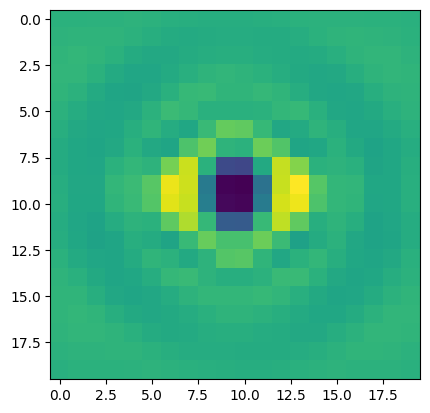

In [15]:
plt.imshow(average[10,:,:])
